# 03 — Độ đo khoảng cách — Euclidean & Mahalanobis

> **Đầu việc 03/6** trong pipeline phát hiện xâm nhập NSL-KDD.

**Mục tiêu**
- Chấm điểm dị biệt bằng khoảng cách tới tâm/phân phối bình thường.
- So sánh Euclidean và Mahalanobis trên cùng dữ liệu.
- Xử lý ma trận hiệp phương sai suy biến bằng pseudo-inverse/regularization.

**Sản phẩm**: `score_euclidean`, `score_mahalanobis` cho train/test — lưu vào `data/processed/`.

## 0. Môi trường

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from nids.config import (CATEGORICAL, DATA_PROCESSED, FEATURES, RANDOM_STATE,
                         REPORTS, FAMILY_ORDER)
from nids.data import load_train_test, to_binary_label, to_family_label, novel_attack_types

pd.set_option("display.float_format", lambda x: f"{x:.4f}")
np.random.seed(RANDOM_STATE)
print("Project root:", PROJECT_ROOT)
print("RANDOM_STATE =", RANDOM_STATE)

Project root: /mnt/Data/ptit/Network_Intrusion&Cyber_Attack_Detection
RANDOM_STATE = 36


## 1. Không gian đặc trưng đầu vào

Dùng `X_train`/`X_test` đã chuẩn hóa từ notebook 01.

In [2]:
# 1) Nạp dữ liệu đã xử lý từ notebook 01-02
X_train = np.load(DATA_PROCESSED / "X_train.npy")
X_test = np.load(DATA_PROCESSED / "X_test.npy")
y_train_binary = np.load(DATA_PROCESSED / "y_train_binary.npy", allow_pickle=True)
y_test_binary = np.load(DATA_PROCESSED / "y_test_binary.npy", allow_pickle=True)
centers = np.load(DATA_PROCESSED / "kmeans_centers.npy")
print("X_train:", X_train.shape, "| X_test:", X_test.shape, "| centers:", centers.shape)

# Chỉ dùng Normal để ước lượng phân phối "bình thường"
X_normal = X_train[y_train_binary == 0]

X_train: (125973, 121) | X_test: (22544, 121) | centers: (8, 121)


## 2. Euclidean

Khoảng cách tới tâm gần nhất (từ K-Means ở notebook 02):

`d(x) = min_k ||x - c_k||_2`

Càng xa tâm càng đáng ngờ.

In [3]:
# 2) Điểm Euclidean: khoảng cách tới tâm gần nhất
from sklearn.metrics import pairwise_distances

def euclidean_scores(X, centers):
    """Với mỗi mẫu, lấy khoảng cách tới tâm gần nhất."""
    distances = pairwise_distances(X, centers, metric="euclidean")
    return distances.min(axis=1)

score_euclidean_train = euclidean_scores(X_train, centers)
score_euclidean_test = euclidean_scores(X_test, centers)
print("score_euclidean train: mean =", round(float(score_euclidean_train.mean()), 3))
print("score_euclidean test:  mean =", round(float(score_euclidean_test.mean()), 3))

score_euclidean train: mean = 3.984
score_euclidean test:  mean = 4.335


## 3. Mahalanobis

`d(x) = sqrt((x - mu)^T * Sigma^-1 * (x - mu))`

Ưu điểm: tính đến phương sai và tương quan giữa các đặc trưng traffic.
Lưu ý: bỏ feature hằng trước khi tính; dùng `np.linalg.pinv` hoặc cộng regularization vào đường chéo.

In [4]:
# 3) Điểm Mahalanobis: khoảng cách có tính phương sai và tương quan
#    d(x) = sqrt( (x-mu)^T * pinv(Sigma) * (x-mu) )
#    Dùng pseudo-inverse thay cho nghịch đảo vì Sigma có thể suy biến.
mu = X_normal.mean(axis=0)
cov = np.cov(X_normal, rowvar=False)
precision = np.linalg.pinv(cov)  # pseudo-inverse, ổn định số học hơn inv()

def mahalanobis_scores(X, mu, precision):
    diff = X - mu
    # (diff @ precision) * diff -> tổng theo hàng = dạng toàn phương
    squared = np.einsum("ij,jk,ik->i", diff, precision, diff)
    squared = np.maximum(squared, 0.0)  # tránh sqrt của số âm do lỗi số học
    return np.sqrt(squared)

score_mahalanobis_train = mahalanobis_scores(X_train, mu, precision)
score_mahalanobis_test = mahalanobis_scores(X_test, mu, precision)
print("score_mahalanobis train: mean =", round(float(score_mahalanobis_train.mean()), 3))
print("score_mahalanobis test:  mean =", round(float(score_mahalanobis_test.mean()), 3))

score_mahalanobis train: mean = 17.699
score_mahalanobis test:  mean = 17.969


## 4. So sánh phân bố điểm Normal vs Attack

Vẽ histogram/boxplot của hai loại điểm trên tập test để xem độ đo nào tách tốt hơn.

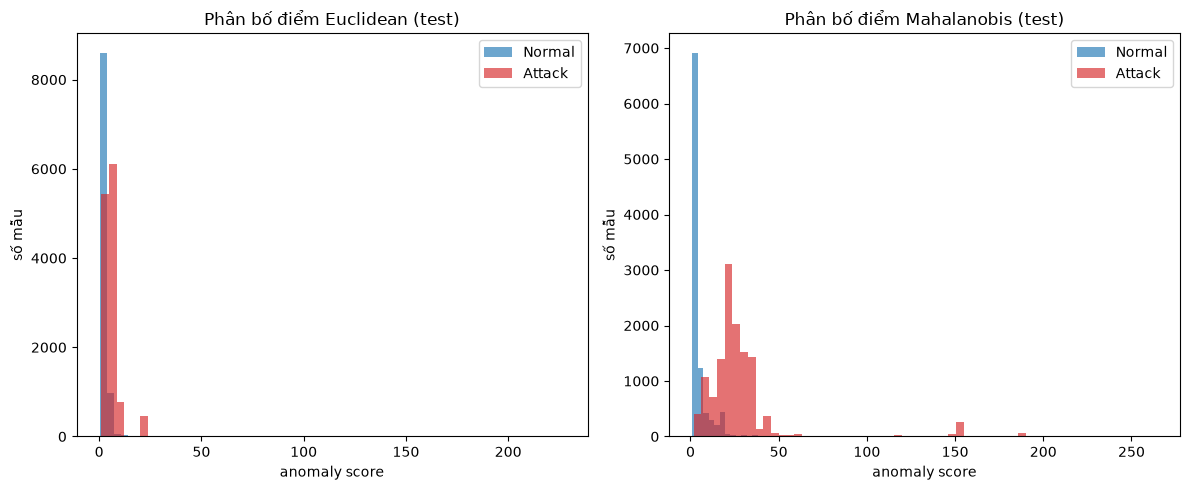

euclidean: trung vị Normal=1.442  Attack=4.984  tỉ lệ=3.46x
mahalanobis: trung vị Normal=1.967  Attack=23.278  tỉ lệ=11.83x
Chuẩn bị lưu điểm dị biệt...
đã lưu 4 file score vào data/processed/


In [5]:
# 4) So sánh phân bố điểm: Normal vs Attack trên test
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, score, title in zip(axes, [score_euclidean_test, score_mahalanobis_test],
                            ["Euclidean", "Mahalanobis"]):
    ax.hist(score[y_test_binary == 0], bins=60, alpha=0.65, label="Normal", color="tab:blue")
    ax.hist(score[y_test_binary == 1], bins=60, alpha=0.65, label="Attack", color="tab:red")
    ax.set_title(f"Phân bố điểm {title} (test)")
    ax.set_xlabel("anomaly score"); ax.set_ylabel("số mẫu"); ax.legend()
fig.tight_layout()
fig.savefig(REPORTS / "figures" / "03_score_distribution.png", dpi=130)
plt.show()

# Nhận xét nhanh bằng trung vị điểm
for name, score in [("euclidean", score_euclidean_test), ("mahalanobis", score_mahalanobis_test)]:
    med_n = float(np.median(score[y_test_binary == 0]))
    med_a = float(np.median(score[y_test_binary == 1]))
    print(f"{name}: trung vị Normal={med_n:.3f}  Attack={med_a:.3f}  tỉ lệ={med_a/max(med_n,1e-9):.2f}x")
print("Chuẩn bị lưu điểm dị biệt...")
# 5) Lưu điểm dị biệt cho cả train và test
np.save(DATA_PROCESSED / "score_euclidean_train.npy", score_euclidean_train)
np.save(DATA_PROCESSED / "score_euclidean_test.npy", score_euclidean_test)
np.save(DATA_PROCESSED / "score_mahalanobis_train.npy", score_mahalanobis_train)
np.save(DATA_PROCESSED / "score_mahalanobis_test.npy", score_mahalanobis_test)
print("đã lưu 4 file score vào data/processed/")

## Checklist hoàn thành

- [x] Đã tính điểm Euclidean tới tâm gần nhất.
- [x] Đã tính điểm Mahalanobis với covariance xử lý suy biến.
- [x] Có so sánh phân bố điểm giữa Normal và Attack.
- [x] Đã lưu score cho cả train và test.